In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                              roc_curve, roc_auc_score, precision_recall_curve, RocCurveDisplay)
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid", context="notebook")
UP_BLUE, UP_RED, UP_GOLD = "#003366", "#BA0C2F", "#C69214"

# EDA


In [124]:
df = pd.read_csv("./data_20230430.csv")
df.columns = ["character_chosen", "least_favorite", "favorite_item", 
              "least_favorite_item", "favorite_track", 
              "least_favorite_track", "prefer_to_play_alone",
              "worried_of_red_shells", "love_Mario_Kart_parties",
              "get_road_rage", "have_time_to_play", "mix_courses",
              "competitive","tatical", "best_driver", "celebrate_loudly",
              "team_matches","love_the_music", "people_target_me",
              "simpathy_for_spiny_shells", "upset_if_I_loose", 
              "just_happy_to_be_involved", "welcoming_person_to_play",
              "only_play_with_favorite_character", "involve_everyone",
              "cheer_others_if_winning", "cheat"
              ]


In [125]:
print(df.shape)
df.head()

(5214, 27)


,character_chosen,least_favorite,favorite_item,least_favorite_item,favorite_track,least_favorite_track,prefer_to_play_alone,worried_of_red_shells,love_Mario_Kart_parties,get_road_rage,...,love_the_music,people_target_me,simpathy_for_spiny_shells,upset_if_I_loose,just_happy_to_be_involved,welcoming_person_to_play,only_play_with_favorite_character,involve_everyone,cheer_others_if_winning,cheat
0,Bowser,Lakitu,Red Shell,Bomerang Flower,Mario Kart Stadium,N64 Rainbow Road,1,4,5,5,...,3,5,4,4,2,5,1,3,4,1
1,Yoshi,Bowser,Bullet Bill,Banana,Sweet Sweet Canyon,Rainbow Road,1,2,5,4,...,4,4,2,4,2,2,1,4,2,1
2,Toad,Donkey Kong,Red Shell,Banana,Shy Guy Falls,Sunshine Airport,1,2,5,4,...,3,1,2,2,4,5,1,4,5,2
3,Bowser,Inkling Girl,Green Shell,Spiny Shell,Mount Wario,Dolphin Shoals,1,2,5,1,...,4,4,5,1,3,4,5,4,4,1
4,Toad,Koopa Trooper,Lightning,Bomb-omb,Rainbow Road,Bowser's Castle,1,3,5,5,...,4,2,1,3,4,4,2,3,4,1


In [126]:
df = df.drop_duplicates()
print(df.shape)

(5214, 27)


In [127]:
print(df["character_chosen"].value_counts())

character_chosen
King Boo           268
Luigi              254
Isabelle           250
Mario              249
Dry Bones          247
Peach              241
Donkey Kong        239
Cat Peach          228
Koopa Troopa       226
Waluigi            215
Daisy              214
Yoshi              208
Tanooki Mario      201
Dry Bowser         190
Toad               187
Rosalina           165
Shy Guy            165
Bowser             158
Morton             157
Roy                147
Lemmy              139
Wario              123
Pink Gold Peach    121
Link               117
Bowser Jr.         108
Iggy               107
Birdo              101
Baby Luigi          97
Ludwig              92
Name: count, dtype: int64


In [128]:
print(df["character_chosen"].unique())
print(df["least_favorite"].unique())
print(df["favorite_item"].unique())
print(df["least_favorite_item"].unique())
print(df["favorite_track"].unique())
print(df["least_favorite_track"].unique())


['Bowser' 'Yoshi' 'Toad' 'Waluigi' 'Peach' 'Luigi' 'Daisy' 'Isabelle'
 'King Boo' 'Donkey Kong' 'Dry Bones' 'Cat Peach' 'Mario' 'Koopa Troopa'
 'Tanooki Mario' 'Dry Bowser' 'Shy Guy' 'Rosalina' 'Pink Gold Peach' 'Roy'
 'Link' 'Baby Luigi' 'Birdo' 'Ludwig' 'Iggy' 'Wario' 'Bowser Jr.' 'Morton'
 'Lemmy']
['Lakitu' 'Bowser' 'Donkey Kong' 'Inkling Girl' 'Koopa Trooper'
 'Metal Mario' 'Waluigi' 'Baby Peach' 'Peach' 'Daisy' 'Wario'
 'Inkling Boy' 'Villager Female' 'Yoshi' 'Luigi' 'Mario' 'Baby Luigi'
 'Link' 'Mii' 'Dry Bones' 'Baby Mario' 'Iggy' 'Pink Gold Peach' 'Wendy'
 'Baby Rosalina' 'Morton' 'Toad' 'Villager Male' 'Shy Guy' 'King Boo'
 'Rosalina' 'Birdo' 'Larry' 'Lemmy' 'Dry Bowser' 'Ludwig' ' King Boo'
 ' Link' ' Larry' ' Inkling Girl' ' Morton' ' Baby Peach' ' Shy Guy'
 ' Wendy' ' Villager Female' ' Wario' ' Yoshi' ' Baby Rosalina'
 ' Rosalina' ' Birdo' ' Dry Bones' ' Baby Luigi' ' Pink Gold Peach'
 ' Lakitu' ' Koopa Trooper' ' Dry Bowser' ' Toad' ' Inkling Boy'
 ' Donkey Kong' ' Iggy'

In [129]:
numerical_features = ["prefer_to_play_alone",
              "worried_of_red_shells", "love_Mario_Kart_parties",
              "get_road_rage", "have_time_to_play", "mix_courses",
              "competitive","tatical", "best_driver", "celebrate_loudly",
              "team_matches","love_the_music", "people_target_me",
              "simpathy_for_spiny_shells", "upset_if_I_loose", 
              "just_happy_to_be_involved", "welcoming_person_to_play",
              "only_play_with_favorite_character", "involve_everyone",
              "cheer_others_if_winning", "cheat"
              ]

categorical_features = [ "least_favorite",
                        "favorite_item", "least_favorite_item",
                        "favorite_track", "least_favorite_track"]

df_encoded = pd.get_dummies(df, columns=categorical_features, drop_first=True, dtype=int)


In [130]:

print(df_encoded.shape)

(5214, 180)


In [131]:
df_encoded.head()

,character_chosen,prefer_to_play_alone,worried_of_red_shells,love_Mario_Kart_parties,get_road_rage,have_time_to_play,mix_courses,competitive,tatical,best_driver,...,least_favorite_track_SNES Donut Plains 3,least_favorite_track_Shy Guy Falls,least_favorite_track_Sunshine Airport,least_favorite_track_Sweet Sweet Canyon,least_favorite_track_Thwomp Ruins,least_favorite_track_Toad Harbour,least_favorite_track_Twisted Mansion,least_favorite_track_Water Park,least_favorite_track_Wii Grumble Volcano,least_favorite_track_Wii Moo Moo Meadows
0,Bowser,1,4,5,5,4,5,5,5,4,...,0,0,0,0,0,0,0,0,0,0
1,Yoshi,1,2,5,4,5,4,5,4,2,...,0,0,0,0,0,0,0,0,0,0
2,Toad,1,2,5,4,2,5,5,5,4,...,0,0,1,0,0,0,0,0,0,0
3,Bowser,1,2,5,1,2,5,2,4,4,...,0,0,0,0,0,0,0,0,0,0
4,Toad,1,3,5,5,2,5,5,4,2,...,0,0,0,0,0,0,0,0,0,0


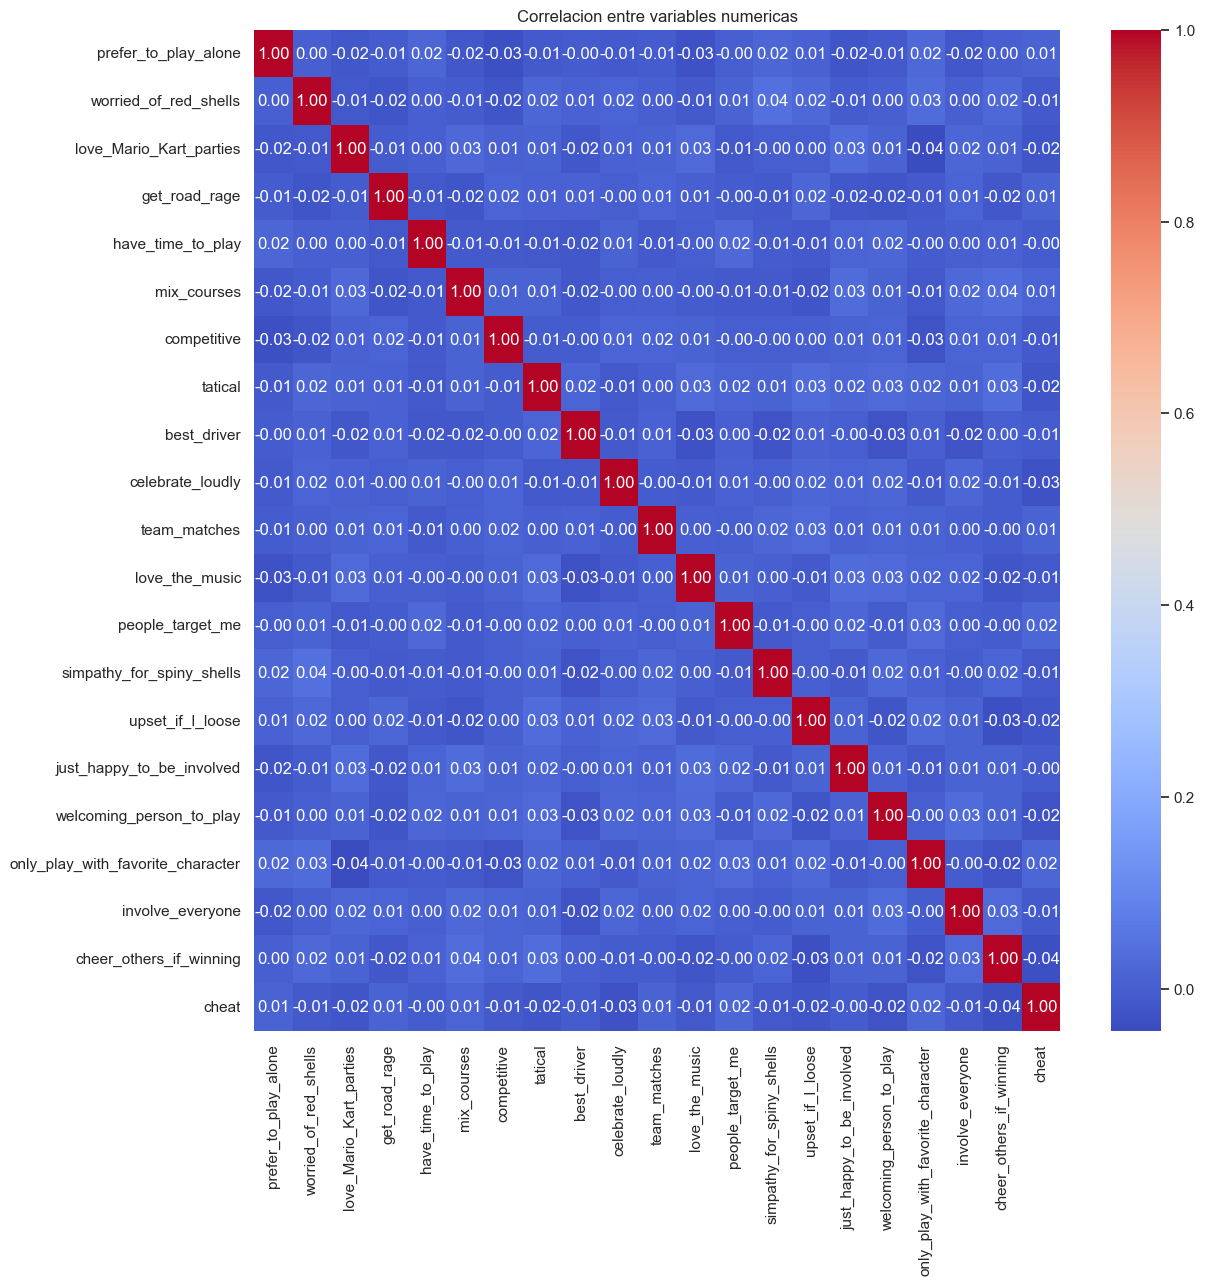

In [132]:
plt.figure(figsize=(13, 13))
sns.heatmap(df[numerical_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlacion entre variables numericas")
plt.show()

# MATRIZ DE DISEÑO

In [133]:
X = df_encoded.drop(columns=["character_chosen"])
y = df_encoded["character_chosen"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# KNN

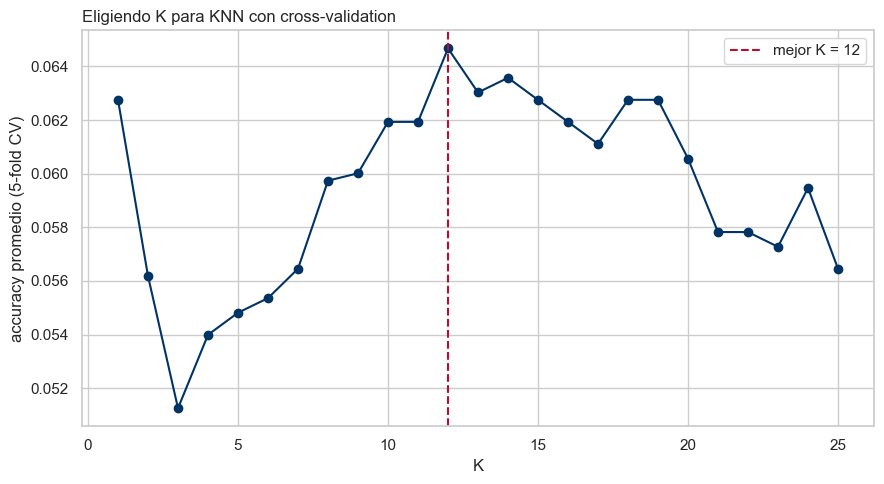

In [134]:
k_grid = range(1, 26)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in k_grid]
best_k = list(k_grid)[int(np.argmax(cv_scores))]

plt.figure(figsize=(9, 5))
plt.plot(list(k_grid), cv_scores, marker="o", color=UP_BLUE)
plt.axvline(best_k, color=UP_RED, ls="--", label=f"mejor K = {best_k}")
plt.xlabel("K")
plt.ylabel("accuracy promedio (5-fold CV)")
plt.title("Eligiendo K para KNN con cross-validation", loc="left")
plt.legend()
plt.tight_layout()
plt.show()

In [135]:
KNN_model = KNeighborsClassifier(n_neighbors=best_k)
KNN_model.fit(X_train, y_train)
y_pred_knn = KNN_model.predict(X_test)

In [136]:
print(accuracy_score(y_test, y_pred_knn))

0.06389776357827476


# Árbol

In [138]:
arbol_completo = DecisionTreeClassifier(random_state=42)
path = arbol_completo.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1]

cv_scores = []
for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    scores = cross_val_score(tree, X_train, y_train, cv=3, scoring="accuracy")
    cv_scores.append(scores.mean())

best_alpha = ccp_alphas[int(np.argmax(cv_scores))]
print(f"Mejor alpha por CV: {best_alpha:.4f}")

model_dt_pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha)
model_dt_pruned.fit(X_train, y_train)

y_pred_dt = model_dt_pruned.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, y_pred_dt), 4))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred_dt, zero_division=0))

Mejor alpha por CV: 0.0008

Accuracy: 0.0792

Reporte de Clasificación:
                  precision    recall  f1-score   support

     Baby Luigi       0.00      0.00      0.00        29
          Birdo       0.00      0.00      0.00        30
         Bowser       0.00      0.00      0.00        47
     Bowser Jr.       0.03      0.03      0.03        32
      Cat Peach       0.00      0.00      0.00        69
          Daisy       0.10      0.14      0.11        64
    Donkey Kong       0.08      0.38      0.13        72
      Dry Bones       0.06      0.03      0.04        74
     Dry Bowser       0.09      0.21      0.12        57
           Iggy       0.00      0.00      0.00        32
       Isabelle       0.00      0.00      0.00        75
       King Boo       0.12      0.09      0.10        81
   Koopa Troopa       0.09      0.22      0.13        68
          Lemmy       0.00      0.00      0.00        42
           Link       0.00      0.00      0.00        35
         Ludwi

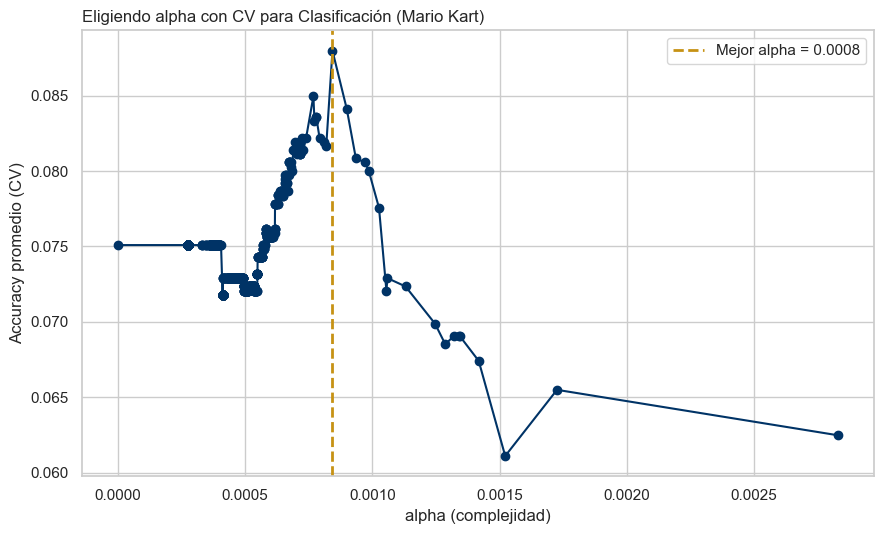

In [139]:
plt.figure(figsize=(9, 5.5))
plt.plot(ccp_alphas, cv_scores, marker="o", color=UP_BLUE)
plt.axvline(best_alpha, color=UP_GOLD, ls="--", lw=2, label=f"Mejor alpha = {best_alpha:.4f}")
plt.xlabel("alpha (complejidad)")
plt.ylabel("Accuracy promedio (CV)")
plt.title("Eligiendo alpha con CV para Clasificación (Mario Kart)", loc="left")
plt.legend()
plt.tight_layout()
plt.show()

In [140]:
arbol_podado = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha).fit(X_train, y_train)
arbol_sin_podar = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

comparacion = pd.DataFrame({
    "modelo": ["Sin podar", "Podado (CV)"],
    "n_hojas": [arbol_sin_podar.get_n_leaves(), arbol_podado.get_n_leaves()],
    "accuracy_test": [
        accuracy_score(y_test, arbol_sin_podar.predict(X_test)),
        accuracy_score(y_test, arbol_podado.predict(X_test)),
    ],
}).round(3)
comparacion

,modelo,n_hojas,accuracy_test
0,Sin podar,2196,0.070
1,Podado (CV),20,0.079


# Observaciones

Pocos datos para muchas clases, no se puede entrenar bien el modelo y por eso nos arroja un accuracy muy bajo. Tampoco se pueden podar los árboles, ya que al intentar simplificar el arbol, solo logra que el accuracy del test baje.